In [19]:
from pymed import PubMed
import pandas as pd

import matplotlib.pyplot as plt

pubmed = PubMed(tool="MyTool", email="my2@email.address")


In [20]:
open_source = sorted(
    [
        "ACT-seq",
        "ASAP-seq",
        "ASTAR-seq",
        "AbPair",
        "BAR-seq",
        "BART-Seq",
        "BAT-seq",
        "BRIF-seq",
        "BacDrop",
        "CEL-Seq2",
        "CEL-seq",
        "CINEMA-OT",
        "CITE-seq",
        "CLEVER-seq",
        "CLInt-seq",
        "CPA-Perturb-seq",
        "CRISP-seq",
        "CROP-seq",
        "CaRPool-seq",
        "CellTag",
        "CellTagging",
        "CoBATCH",
        "Combi-seq",
        "Convert-seq",
        "CytoSeq",
        "DART-Seq",
        "DOGMA-seq",
        "DR-seq",
        "Dip-C",
        "DoTA-seq",
        "DroNC-Seq",
        "Drop-Chip",
        "Drop-seq",
        "Droplet-based scATAC-seq",
        "ECCITE-seq",
        "EasySCI-RNA",
        "FB5P-seq",
        "FFPE-CUTAC",
        "FIN-Seq",
        "FISSEQ",
        "FRISCR",
        "FixNCut",
        "G&T-Seq",
        "GAGE-seq",
        "Geo-seq",
        "Hi-SCL",
        "HyDrop",
        "HyPR-seq",
        "INSTA-seq",
        "INs-seq",
        "ISSAAC-seq",
        "LIBRA-seq",
        "LR-Split-seq",
        "Live-seq",
        "M3-seq",
        "MARS-seq",
        "MARS-seq2.0",
        "MATQ-seq",
        "MAbID",
        "META-CS",
        "MIX-Seq",
        "MULTI-seq",
        "Microbe-seq",
        "MoonTag/SunTag",
        "Mux-Seq",
        "NEAT-seq",
        "NNT-seq",
        "NanoPARE",
        "PAIso-seq",
        "PERFF-seq",
        "PETRI-seq",
        "PIP-seq",
        "PLAYR",
        "PMA/SMA",
        "PRDD-seq",
        "Paired-Seq",
        "Patch-seq",
        "Perturb-ATAC",
        "Pop-C",
        "ProBac-seq",
        "Prox-seq",
        "Quartz-Seq",
        "Quartz-Seq2",
        "RABID-seq",
        "RAGE-Seq",
        "RamDA-seq",
        "RevGel-seq",
        "SC3-seq",
        "SCI-LITE",
        "SCITO-seq",
        "SCoPE2",
        "SEC-seq",
        "SIDR-seq",
        "SINC-seq",
        "SMART-seq",
        "SNARE-seq",
        "SPEAR-ATAC",
        "SPLiT-seq",
        "STING-seq",
        "STRT-seq",
        "STRT-seq-2i",
        "SUM-seq",
        "SUPeR-seq",
        "ScarTrace",
        "Sci-Hi-C",
        "Seq-Well",
        "SiC-seq",
        "Simplified-Drop-seq",
        "Slide-seq",
        "Slide-tags",
        "Smart-RRBS",
        "Smart-seq-total",
        "Smart-seq2",
        "SnFFPE-Seq",
        "SnapATAC2",
        "TAP-seq",
        "TARGET-seq",
        "TAS-Seq",
        "TEA-seq",
        "TIP-Seq",
        "TISCC-seq",
        "TM3'seq",
        "TRAPS-seq",
        "TetTCR-SeqHD",
        "Tn5Prime",
        "Trac-looping",
        "TracerSeq",
        "Tuba-seq",
        "Well-Temp-seq",
        "dTn-Seq",
        "dsciATAC-seq",
        "inDrop",
        "iscCOOL-seq",
        "itChIP-seq",
        "mEnrich-seq",
        "mcSCRB-seq",
        "microSPLiT",
        "mtscATAC-seq",
        "nanoSplits",
        "netNMF-sc",
        "sMicro-C",
        "sc paired microRNA-mRNA",
        "sc-GEM",
        "sc-m3c-seq",
        "scBS-seq",
        "scCAT-seq",
        "scCOOL-seq",
        "scCUT&TAG-pro",
        "scChIC-seq",
        "scDam&T-seq",
        "scDamID&T",
        "scGESTALT",
        "scGET-SEQ",
        "scHiC",
        "scISOr-Seq",
        "scM&T-seq",
        "scMNase-seq",
        "scMTseq",
        "scMethylation",
        "scMspJI-seq",
        "scNMT triple omics",
        "scNOMe-seq",
        "scNT-seq",
        "scPLAT",
        "scSNV-Seq",
        "scSNV-seq",
        "scSPLAT",
        "scSPRITE",
        "scTAM-seq",
        "scTEM-seq",
        "scTHS-seq",
        "scTaILoR-seq",
        "scTrio-seq",
        "scWGBS",
        "sci-ATAC-seq",
        "sci-CAR",
        "sci-MET",
        "sci-Plex",
        "sci-RNA-seq",
        "sci-RNA-seq3",
        "sci-fate",
        "sci-fate",
        "sciMETv2",
        "scifi-RNA-seq",
        "smRandom-seq",
        "sn-m3C-seq",
        "snPATHO-Seq",
        "snhmC-seq",
        "snmC-seq",
        "snmC-seq2",
        "snmCAT-seq",
        "vDip-C",
        "viscRNA-seq",
        "yscRNA-SEQ",
    ]
)

biorad = ["bio-rad"]

In [21]:
import os
import json
import time
import requests

QUERY_LOG_FILE = "pubmed_queries.txt"  # Stores all executed queries
RESULTS_FILE = "pubmed_results.csv"    # Stores all article results

def load_previous_queries():
    """Load previously executed queries from the text file."""
    if os.path.exists(QUERY_LOG_FILE):
        with open(QUERY_LOG_FILE, "r") as f:
            return set(line.strip() for line in f.readlines())
    return set()

def save_new_query(query):
    """Append a single new query to the text file."""
    with open(QUERY_LOG_FILE, "a") as f:
        f.write(query + "\n")

def load_results():
    """Load previously saved results from disk."""
    if os.path.exists(RESULTS_FILE):
        return pd.read_csv(RESULTS_FILE)
    return pd.DataFrame()

def save_results(df):
    """Save the DataFrame to disk in CSV format."""
    df.to_csv(RESULTS_FILE, index=False)

def fetch_articles_df(pubmed_queries):
    """Fetch articles from PubMed, avoid redundant queries, and store results persistently."""
    previous_queries = load_previous_queries()
    df_existing = load_results()

    # Separate new and old queries
    new_queries = [q for q in pubmed_queries if q not in previous_queries]
    old_queries = [q for q in pubmed_queries if q in previous_queries]

    # If no new queries, return existing results for old queries
    if not new_queries:
        print("All queries have already been executed. Loading saved results.")
        return df_existing[df_existing["matched_keywords"].apply(lambda x: any(q in x for q in old_queries))]

    for i, pubmed_query in enumerate(new_queries):
        print(f"Query {i + 1}/{len(new_queries)}: {pubmed_query}")

        try:
            # Introduce a small delay to avoid rate limits
            time.sleep(1)  

            response = pubmed.query(pubmed_query, max_results=99999)

            # Check if response is valid JSON
            if isinstance(response, requests.Response):
                if response.status_code != 200:
                    print(f"Warning: Non-200 response for query '{pubmed_query}' (Status: {response.status_code})")
                    print(f"Response Text: {response.text[:500]}")
                    continue  # Skip this query and move to next

                # Try parsing JSON and identify bad characters
                try:
                    response_json = response.json()
                except json.JSONDecodeError as e:
                    print("\n--- JSON Decode Error ---")
                    print(f"Query: {pubmed_query}")
                    print(f"Error message: {e}")
                    
                    # Get the problematic character position
                    error_pos = e.pos  
                    raw_response = response.text

                    # Print the full response if short, else truncate
                    print(f"Raw response (first 500 chars): {raw_response[:500]}")
                    
                    # Highlight the exact character causing the error
                    if error_pos < len(raw_response):
                        print(f"Offending character at position {error_pos}: '{raw_response[error_pos]}' (ASCII: {ord(raw_response[error_pos])})")
                    
                    print("-------------------------\n")
                    continue  # Skip this query and proceed

            else:
                # If response isn't a requests object, ensure it's iterable
                results = list(response)

        except Exception as e:
            print(f"Unexpected error for query '{pubmed_query}': {e}")
            continue  # Skip this query and proceed

        articles_dict = {}

        for article in results:
            article_dict = article.toDict()
            pubmed_id = article_dict["pubmed_id"]

            if pubmed_id in articles_dict:
                articles_dict[pubmed_id]["matched_keywords"].append(pubmed_query)
            else:
                article_dict["matched_keywords"] = [pubmed_query]
                articles_dict[pubmed_id] = article_dict

        # Convert new results to DataFrame
        df_new = pd.DataFrame(articles_dict.values())

        if not df_new.empty:
            # Remove bioRxiv entries
            df_new = df_new[~df_new["journal"].str.contains("bioRxiv", case=False, na=False)]
            df_new["publication_date"] = pd.to_datetime(df_new["publication_date"], errors="coerce")

            # Merge with existing data, ensuring no duplicates
            df_existing = pd.concat([df_existing, df_new], ignore_index=True).drop_duplicates(subset=["pubmed_id"])
            save_results(df_existing)  # Save **immediately after every query**
            save_new_query(pubmed_query)  # Save the query **immediately after every query**

    # Return results for both new and old queries
    return df_existing[df_existing["matched_keywords"].apply(lambda x: any(q in x for q in pubmed_queries))]


In [22]:
df_open_source = fetch_articles_df(open_source)
df_open_source["query_category"] = "Open Source"

pubmed_queries = ["bio-rad AND single-cell", "biorad AND single-cell"]
df_biorad = fetch_articles_df(pubmed_queries)
df_biorad["query_category"] = "Bio-Rad"

pubmed_queries = ["10x genomics AND single-cell"]
df_10x = fetch_articles_df(pubmed_queries)
df_10x["query_category"] = "10x Genomics"

pubmed_queries = ["RNA-seq"]
df_rnaseq = fetch_articles_df(pubmed_queries)
df_rnaseq["query_category"] = "RNA-seq"

pubmed_queries = ["ATAC-seq OR DNAse-seq OR CHIP-seq"]
df_atac = fetch_articles_df(pubmed_queries)
df_atac["query_category"] = "ATAC-seq/DNase-seq"

df_combined = pd.concat(
    [df_open_source, df_biorad, df_10x, df_rnaseq, df_atac], ignore_index=True
)

Query 1/194: ACT-seq
Query 2/194: ASAP-seq
Query 3/194: ASTAR-seq
Query 4/194: AbPair
Query 5/194: BAR-seq
Query 6/194: BART-Seq
Query 7/194: BAT-seq
Query 8/194: BRIF-seq
Query 9/194: BacDrop
Query 10/194: CEL-Seq2
Query 11/194: CEL-seq
Query 12/194: CINEMA-OT
Query 13/194: CITE-seq
Query 14/194: CLEVER-seq
Query 15/194: CLInt-seq
Query 16/194: CPA-Perturb-seq
Query 17/194: CRISP-seq
Query 18/194: CROP-seq
Query 19/194: CaRPool-seq
Query 20/194: CellTag
Query 21/194: CellTagging
Query 22/194: CoBATCH
Query 23/194: Combi-seq
Query 24/194: Convert-seq
Query 25/194: CytoSeq
Query 26/194: DART-Seq
Query 27/194: DOGMA-seq
Query 28/194: DR-seq
Query 29/194: Dip-C
Query 30/194: DoTA-seq
Query 31/194: DroNC-Seq
Query 32/194: Drop-Chip
Query 33/194: Drop-seq
Query 34/194: Droplet-based scATAC-seq
Query 35/194: ECCITE-seq
Query 36/194: EasySCI-RNA
Query 37/194: FB5P-seq
Query 38/194: FFPE-CUTAC
Query 39/194: FIN-Seq
Query 40/194: FISSEQ
Query 41/194: FRISCR
Query 42/194: FixNCut
Query 43/194: G

In [23]:
keyword_counts = df.explode("matched_keywords")["matched_keywords"].value_counts()

print(keyword_counts)


NameError: name 'df' is not defined

In [18]:
# Convert 'publication_date' column to datetime format

df["publication_date"] = pd.to_datetime(df["publication_date"])
# Filter out dates before the year 2000
df = df[df["publication_date"] >= "2000-01-01"]

/var/folders/p_/flb84jgs2_jbb5_gnn1645jw0000gn/T/ipykernel_65598/1442984666.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["publication_date"] = pd.to_datetime(df["publication_date"])
/var/folders/p_/flb84jgs2_jbb5_gnn1645jw0000gn/T/ipykernel_65598/1442984666.py:3: FutureWarning: 'Y' is deprecated and will be removed in a future version, please use 'YE' instead.
  monthly_counts = df.resample("Y", on="publication_date").size()


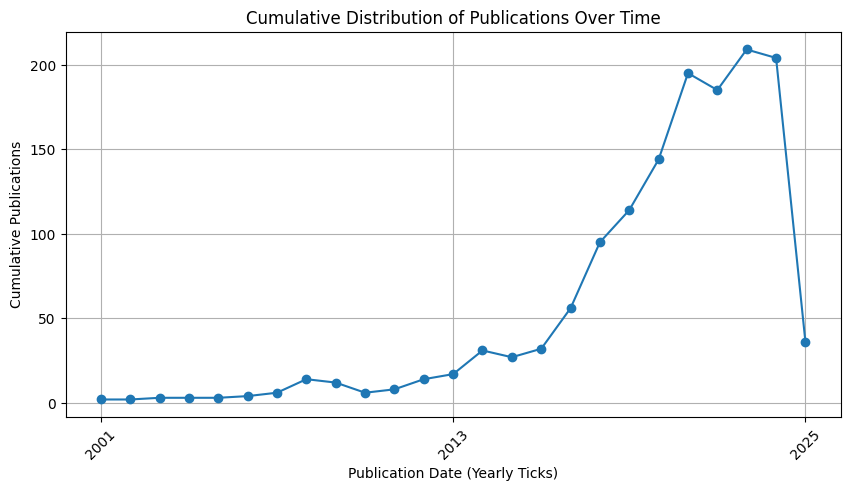

In [ ]:
df["publication_date"] = pd.to_datetime(df["publication_date"])

monthly_counts = df.resample("Y", on="publication_date").size()

plt.figure(figsize=(10, 5))
plt.plot(monthly_counts.index, monthly_counts.values, marker="o", linestyle="-")

plt.xticks(
    monthly_counts.index[::12], monthly_counts.index.strftime("%Y")[::12], rotation=45
)

plt.xlabel("Publication Date (Yearly Ticks)")
plt.ylabel("Cumulative Publications")
plt.title("Cumulative Distribution of Publications Over Time")
plt.grid(True)
plt.show()


/var/folders/p_/flb84jgs2_jbb5_gnn1645jw0000gn/T/ipykernel_65598/1757428990.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["publication_date"] = pd.to_datetime(df["publication_date"])
/var/folders/p_/flb84jgs2_jbb5_gnn1645jw0000gn/T/ipykernel_65598/1757428990.py:3: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  monthly_counts = df.resample("M", on="publication_date").size().cumsum()


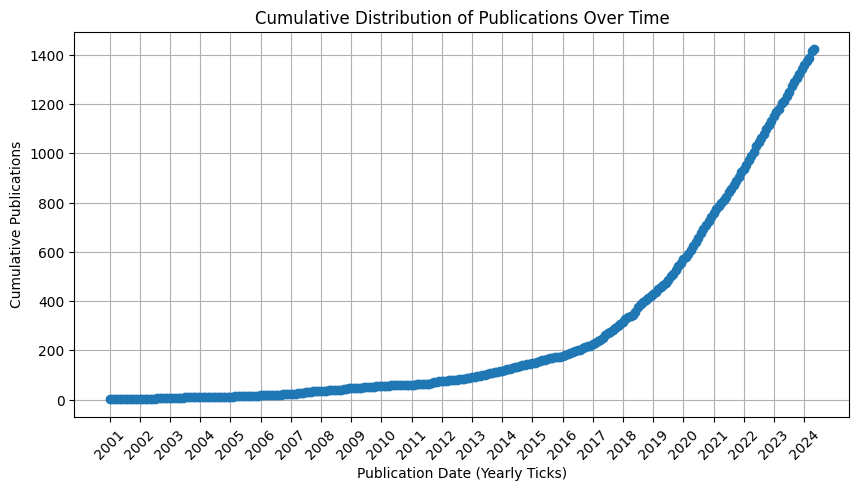

In [20]:
df["publication_date"] = pd.to_datetime(df["publication_date"])

monthly_counts = df.resample("M", on="publication_date").size().cumsum()

plt.figure(figsize=(10, 5))
plt.plot(monthly_counts.index, monthly_counts.values, marker="o", linestyle="-")

plt.xticks(
    monthly_counts.index[::12], monthly_counts.index.strftime("%Y")[::12], rotation=45
)

plt.xlabel("Publication Date (Yearly Ticks)")
plt.ylabel("Cumulative Publications")
plt.title("Cumulative Distribution of Publications Over Time")
plt.grid(True)
plt.show()


In [8]:
df.sort_values("publication_date")

NameError: name 'df' is not defined